In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/return-fraud-research"

folders = [
    "data/raw",
    "data/processed",
    "data/samples",
    "notebooks",
    "results/dip",
    "results/optimization",
    "results/network",
    "models",
    "figures",
    "research"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Project structure created.")

Project structure created.


In [ ]:
!find "/content/drive/MyDrive/return-fraud-research" -maxdepth 3 -type d

/content/drive/MyDrive/return-fraud-research
/content/drive/MyDrive/return-fraud-research/data
/content/drive/MyDrive/return-fraud-research/data/raw
/content/drive/MyDrive/return-fraud-research/data/processed
/content/drive/MyDrive/return-fraud-research/data/samples
/content/drive/MyDrive/return-fraud-research/notebooks
/content/drive/MyDrive/return-fraud-research/results
/content/drive/MyDrive/return-fraud-research/results/dip
/content/drive/MyDrive/return-fraud-research/results/optimization
/content/drive/MyDrive/return-fraud-research/results/network
/content/drive/MyDrive/return-fraud-research/models
/content/drive/MyDrive/return-fraud-research/figures
/content/drive/MyDrive/return-fraud-research/research


In [ ]:
!pip install -q \
    numpy \
    pandas \
    opencv-python \
    scikit-image \
    scikit-learn \
    matplotlib \
    seaborn \
    Pillow \
    tqdm

In [3]:


import skimage
import sklearn

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

print("All libraries loaded successfully.")

All libraries loaded successfully.


In [ ]:
import sys
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())  #record the invironment in research docu.

!nvidia-smi

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
/bin/bash: line 1: nvidia-smi: command not found


In [4]:
import os

print("GPU:")
os.system("lspci | grep -i nvidia")

GPU:


256

In [5]:
import tensorflow as tf

print("GPU devices:")
print(tf.config.list_physical_devices('GPU'))

GPU devices:
[]


In [6]:
BASE_DIR = "/content/drive/MyDrive/return-fraud-research"

DATASET_DIR = os.path.join(
    BASE_DIR,
    "data",
    "raw",
    "MVTec_AD"
)

BOTTLE_DIR = os.path.join(
    DATASET_DIR,
    "bottle"
)

print("Dataset directory:")
print(DATASET_DIR)

print("\nBottle directory:")
print(BOTTLE_DIR)

Dataset directory:
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD

Bottle directory:
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle


In [8]:
if os.path.exists(BOTTLE_DIR):
    print("✓ Bottle dataset found!")
else:
    print("✗ Bottle dataset not found.")
    print("\nExpected location:")
    print(BOTTLE_DIR)

✗ Bottle dataset not found.

Expected location:
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
import os

BASE_DIR = "/content/drive/MyDrive/return-fraud-research"
DATASET_DIR = os.path.join(BASE_DIR, "data", "raw", "MVTec_AD")
BOTTLE_DIR = os.path.join(DATASET_DIR, "bottle")

print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Bottle exists:", os.path.exists(BOTTLE_DIR))

print("\nDataset path:")
print(DATASET_DIR)

print("\nBottle path:")
print(BOTTLE_DIR)

Dataset exists: True
Bottle exists: True

Dataset path:
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD

Bottle path:
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle


In [14]:
import os

print("Contents of bottle folder:")
for item in sorted(os.listdir(BOTTLE_DIR)):
    print(" -", item)

Contents of bottle folder:
 - ground_truth
 - license.txt
 - readme.txt
 - test
 - train


In [15]:
TRAIN_DIR = os.path.join(BOTTLE_DIR, "train")
TEST_DIR = os.path.join(BOTTLE_DIR, "test")
GT_DIR = os.path.join(BOTTLE_DIR, "ground_truth")

print("Train exists:", os.path.exists(TRAIN_DIR))
print("Test exists:", os.path.exists(TEST_DIR))
print("Ground truth exists:", os.path.exists(GT_DIR))

Train exists: True
Test exists: True
Ground truth exists: True


In [16]:
print("Contents of bottle folder:\n")

for item in sorted(os.listdir(BOTTLE_DIR)):
    print(" -", item)

Contents of bottle folder:

 - ground_truth
 - license.txt
 - readme.txt
 - test
 - train


In [17]:
print("TRAIN CATEGORIES:\n")   #inspect train categories

train_categories = sorted(os.listdir(TRAIN_DIR))

for category in train_categories:
    category_path = os.path.join(TRAIN_DIR, category)

    if os.path.isdir(category_path):
        print(" -", category)

TRAIN CATEGORIES:

 - good


In [18]:
print("TEST CATEGORIES:\n")  #test

test_categories = sorted(os.listdir(TEST_DIR))

for category in test_categories:
    category_path = os.path.join(TEST_DIR, category)

    if os.path.isdir(category_path):
        print(" -", category)

TEST CATEGORIES:

 - broken_large
 - broken_small
 - contamination
 - good


In [19]:
def count_images(folder):
    valid_extensions = (".png", ".jpg", ".jpeg", ".bmp")

    count = 0

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(valid_extensions):
                count += 1

    return count


print("Training images:", count_images(TRAIN_DIR))
print("Testing images:", count_images(TEST_DIR))
print("Ground-truth images:", count_images(GT_DIR))

Training images: 209
Testing images: 83
Ground-truth images: 63


In [20]:
print("TRAIN IMAGE COUNTS") #count image by category
print("=" * 40)

for category in sorted(os.listdir(TRAIN_DIR)):

    category_path = os.path.join(TRAIN_DIR, category)

    if os.path.isdir(category_path):

        count = count_images(category_path)

        print(f"{category:20s} : {count}")

TRAIN IMAGE COUNTS
good                 : 209


In [21]:
print("\nTEST IMAGE COUNTS")
print("=" * 40)

for category in sorted(os.listdir(TEST_DIR)):

    category_path = os.path.join(TEST_DIR, category)

    if os.path.isdir(category_path):

        count = count_images(category_path)

        print(f"{category:20s} : {count}")


TEST IMAGE COUNTS
broken_large         : 20
broken_small         : 22
contamination        : 21
good                 : 20


In [24]:
def get_image_paths(folder):  #to get image path
    valid_extensions = (".png", ".jpg", ".jpeg", ".bmp")

    image_paths = []

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(valid_extensions):

                image_paths.append(
                    os.path.join(root, file)
                )

    return sorted(image_paths)

In [25]:
NORMAL_DIR = os.path.join(
    TEST_DIR,
    "good"
)

normal_images = get_image_paths(NORMAL_DIR)

print("Number of normal test images:", len(normal_images))

print("\nFirst 5 images:")

for path in normal_images[:5]:
    print(path)

Number of normal test images: 20

First 5 images:
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/good/000.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/good/001.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/good/002.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/good/003.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/good/004.png


In [26]:
anomaly_images = []

for category in sorted(os.listdir(TEST_DIR)):

    if category == "good":
        continue

    category_path = os.path.join(
        TEST_DIR,
        category
    )

    if os.path.isdir(category_path):

        paths = get_image_paths(category_path)

        anomaly_images.extend(paths)

print("Total anomaly images:", len(anomaly_images))

print("\nFirst 10 anomaly images:")

for path in anomaly_images[:10]:
    print(path)

Total anomaly images: 63

First 10 anomaly images:
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/000.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/001.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/002.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/003.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/004.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/005.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/006.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/007.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_large/008.png
/content/drive/MyDrive/return-fraud-research/data/raw/MVTec_AD/bottle/test/broken_lar

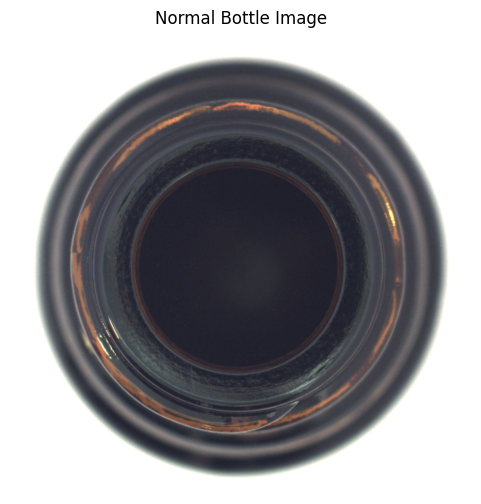

In [27]:
image_path = normal_images[0]  #normal bottle

image = cv2.imread(image_path)

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(6, 6))

plt.imshow(image_rgb)

plt.title("Normal Bottle Image")

plt.axis("off")

plt.show()

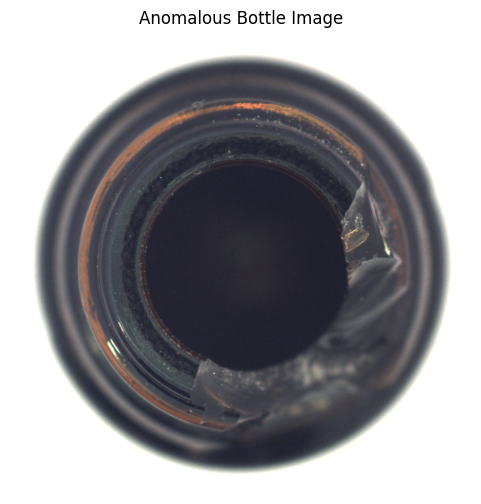

In [28]:
anomaly_path = anomaly_images[0]  #anomaly in bottle

image = cv2.imread(anomaly_path)

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(6, 6))

plt.imshow(image_rgb)

plt.title("Anomalous Bottle Image")

plt.axis("off")

plt.show()

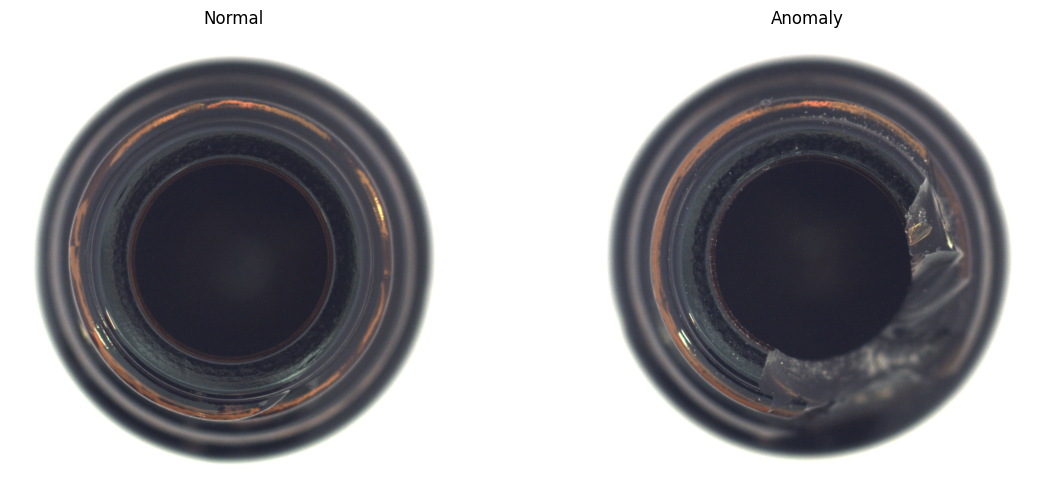

In [29]:
normal = cv2.imread(normal_images[0])  #normal vs anomaly
normal = cv2.cvtColor(normal, cv2.COLOR_BGR2RGB)

anomaly = cv2.imread(anomaly_images[0])
anomaly = cv2.cvtColor(anomaly, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(normal)
plt.title("Normal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(anomaly)
plt.title("Anomaly")
plt.axis("off")

plt.tight_layout()
plt.show()

In [30]:
normal_image = cv2.imread(normal_images[0])

anomaly_image = cv2.imread(anomaly_images[0])

print("Normal image shape:", normal_image.shape)
print("Anomaly image shape:", anomaly_image.shape)

Normal image shape: (900, 900, 3)
Anomaly image shape: (900, 900, 3)


In [31]:
RESULTS_DIP_DIR = os.path.join(    #result folder
    BASE_DIR,
    "results",
    "dip"
)

os.makedirs(
    RESULTS_DIP_DIR,
    exist_ok=True
)

print("Results directory:")
print(RESULTS_DIP_DIR)

Results directory:
/content/drive/MyDrive/return-fraud-research/results/dip


In [32]:
dataset_statistics = []

for category in sorted(os.listdir(TEST_DIR)):

    category_path = os.path.join(
        TEST_DIR,
        category
    )

    if os.path.isdir(category_path):

        count = count_images(category_path)

        dataset_statistics.append({
            "split": "test",
            "category": category,
            "image_count": count
        })


stats_df = pd.DataFrame(
    dataset_statistics
)

stats_path = os.path.join(
    RESULTS_DIP_DIR,
    "bottle_dataset_statistics.csv"
)

stats_df.to_csv(
    stats_path,
    index=False
)

print("Saved:")
print(stats_path)

display(stats_df)

Saved:
/content/drive/MyDrive/return-fraud-research/results/dip/bottle_dataset_statistics.csv


,split,category,image_count
0,test,broken_large,20
1,test,broken_small,22
2,test,contamination,21
3,test,good,20
